# 01 - Data Exploration
Goal: understand the MovieLens small dataset before building any models.\
Questions: how many users and movies, how ratings are distributed, how sparse data is.

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Load the data

In [2]:
ratings_df = pd.read_csv('../data/ml-latest-small/ratings.csv')
movies_df = pd.read_csv('../data/ml-latest-small/movies.csv')

In [3]:
# Print the first few rows of rating
ratings_df.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [4]:
# Print the first few rows of movies
movies_df.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [5]:
# Print shape of each dataframe (row, column)
print(ratings_df.shape)
print(movies_df.shape)

(100836, 4)
(9742, 3)


## Notes
- Ratings timestamps are Unix time (sec since 1970), will need converting to dates
- Genres are pipe-separated in one column

## Basic Stats

1. How many unique users and movies are in the ratings?  
Guess: Users should be less than movies (users rating more than one movie). Ideally the number of unique movies in rating is the same as the total number of movies (all movies have a rating).

In [6]:
# Print how many unique values for userId in ratings dataframe 
num_of_users = ratings_df['userId'].unique().size           # unique returns np array and size give total num of indexes
print(f"Number of Users: {num_of_users}")

# Print how many unique values for movie in ratings dataframe
num_of_rated_movies = ratings_df['movieId'].unique().size   # unique returns np array and size give total num of indexes
print(f"Number of Rated Movies: {num_of_rated_movies}")

# Print num of unrated movies
total_movies = movies_df['movieId'].nunique()               # nunique = unique().size
num_of_unrated_movies = total_movies - num_of_rated_movies
print(f"Number of Unrated Movies: {num_of_unrated_movies}")

# Print avg num of ratings per user
total_ratings = ratings_df.shape[0]                         # shape = [row, column]
avg_num_of_ratings_per_user = total_ratings / num_of_users
print(f"Average number of Ratings per User: {total_ratings / num_of_users:.2f}")

Number of Users: 610
Number of Rated Movies: 9724
Number of Unrated Movies: 18
Average number of Ratings per User: 165.30


Conclusion: Not all movies have been rated, there are 18 unrated movies. Users are very active, with each user averaging about 165 ratings. 

2. How are ratings distributed?  
Guess: The first 5 ratings show decimals to one point. I am guessing that rating are out of 5 stars, allowing for half stars. I would guess the distribution is polarized. When rating anything, people tend to leave ratings to give high praise or express major issues.

In [7]:
# Print all unique values to see the rating scale
print(ratings_df['rating'].unique())

[4.  5.  3.  2.  1.  4.5 3.5 2.5 0.5 1.5]


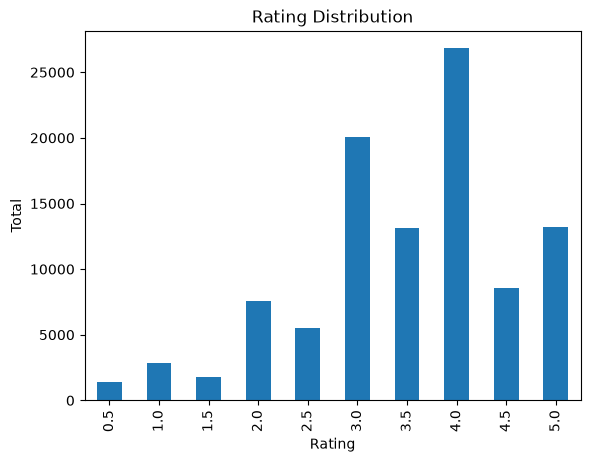

In [8]:
# Get counts for each value, sort based on index (ascending), then make a bar plot.
ratings_df['rating'].value_counts().sort_index().plot.bar()
plt.title('Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Total')
plt.show()

Conclusion: My initial guess of ratings being polarized was wrong. Ratings range from 0.5-5.0 stars. The distribution leans towards positive reviews, showing a bias towards people rating movies they enjoy and not rating movies they do not. Also, whole star ratings are more common than half star ratings.

3. How many ratings does each user and each movie have?  
Guess: Normal bell curve distribution for both ratings per user. For movies more popular movies would have more ratings than less popular movies.

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64


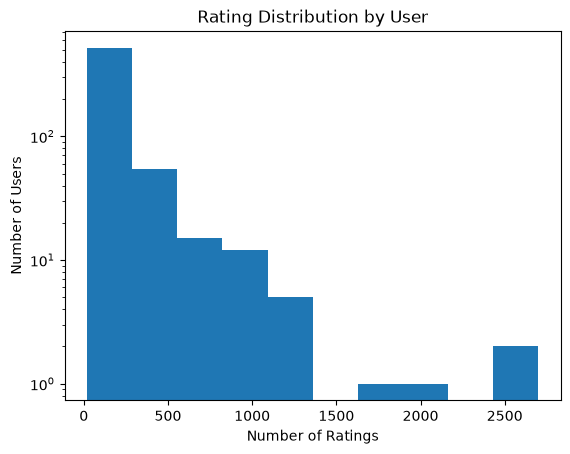

Percentage of ratings from top 10 percent: 47.72


In [9]:
# Group by user ID and count the number of occurrence
num_of_ratings_per_user = ratings_df.groupby('userId').size()

# Print distribution stats
ratings_df_stats = num_of_ratings_per_user.describe()
print(ratings_df_stats)

# Show histogram of ratings per user
num_of_ratings_per_user.plot.hist(logy=True)
plt.title('Rating Distribution by User')
plt.xlabel('Number of Ratings')
plt.ylabel('Number of Users')
plt.show()

# Sort users by number of ratings in descending order, take the top 10%, and add the total number of ratings
top_ten_user_count = int(num_of_users * 0.1)
top_ten_total_ratings_users = num_of_ratings_per_user.sort_values(ascending=False).head(n=top_ten_user_count).sum()
top_ten_percent_of_users = (top_ten_total_ratings_users / total_ratings) * 100
print(f'Percentage of ratings from top 10 percent: {top_ten_percent_of_users:.2f}')

count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64


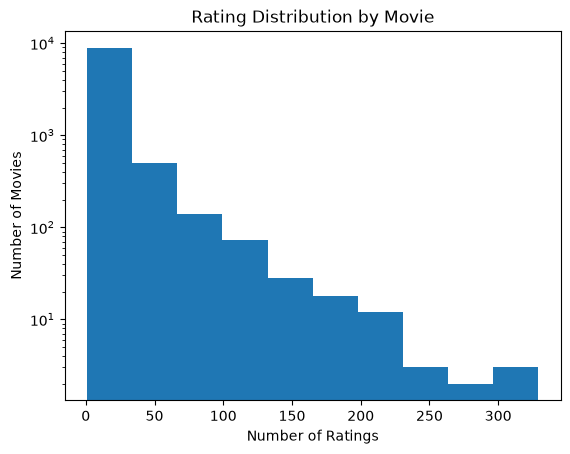

Percentage of ratings from top 10 percent: 60.02


In [10]:
# Group by movie ID and count the number of occurrence
num_of_ratings_per_movie = ratings_df.groupby('movieId').size()

# Print distribution stats
movies_df_stats = num_of_ratings_per_movie.describe()
print(movies_df_stats)

# Show histogram of ratings per movie
num_of_ratings_per_movie.plot.hist(logy=True)
plt.title('Rating Distribution by Movie')
plt.xlabel('Number of Ratings')
plt.ylabel('Number of Movies')
plt.show()

# Sort movies by number of ratings in descending order, take the top 10%, and add the total number of ratings
top_ten_movie_count = int(num_of_rated_movies * 0.1)
top_ten_total_ratings_movies = num_of_ratings_per_movie.sort_values(ascending=False).head(n=top_ten_movie_count).sum()
top_ten_percentage_of_movies = (top_ten_total_ratings_movies / total_ratings) * 100
print(f'Percentage of ratings from top 10 percent: {top_ten_percentage_of_movies:.2f}')

Conclusion: Both movies and user ratings are influenced by extremes. My guess was incorrect for rating distribution, but correct for movie distribution. The top 10% of users make up about 48% of the ratings and the top 10% of movies make up about 60% of the ratings.

4. How sparse is the data?  
Guess: 

Conclusion: 

5. What time period does the data cover?  
Guess: 

Conclusion